# Test IPR Gram-matrix plotting
 
 This notebook tests `plot_gram_matrices.py` for standard processed IPR kernels for TFIM and Heisenberg, then covers thermal IPR and HS kernels from raw and processed data.

In [1]:
from pathlib import Path
import importlib
import sys

cwd = Path.cwd()
script_dir = cwd if (cwd / 'plot_gram_matrices.py').exists() else cwd / 'scripts'
if str(script_dir) not in sys.path:
    sys.path.insert(0, str(script_dir))

import data_config
import plot_gram_matrices as gram_plots
importlib.reload(data_config)
importlib.reload(gram_plots)

from data_config import available_thermal_betas, available_thermal_l_values
from plot_gram_matrices import (
    compute_ipr_gram_matrix,
    compute_thermal_gram_matrix,
    compute_thermal_hs_gram_matrix,
    compute_thermal_ipr_gram_matrix,
    plot_ipr_gram_matrix,
    plot_ipr_gram_matrices_up_to,
    plot_thermal_gram_matrix,
    plot_thermal_gram_matrices,
)

# print('Using:', gram_plots.__file__)
%matplotlib inline

## Standard processed IPR Grams
 
 The standard Gram functions use the interpolated processed datasets configured in `data_config.DATASETS`. Dataset keys are `tfim1d`, `tfim2d`, and `heisenberg`. Basis choices are explicit lists, for example `["IPR X", "IPR Z"]` or `["IPR XY", "IPR Z"]`.

### TFIM 1D: compute one Gram
 
 This builds the normalized IPR kernel from `[IPR X, IPR Z]` features for one processed TFIM chain size.

In [2]:
tfim_gram = compute_ipr_gram_matrix(
    dataset='tfim1d',
    L=10,
    basis=['IPR X', 'IPR Z'],
    normalize=True,
)

print('K shape:', tfim_gram['K'].shape)
print('features shape:', tfim_gram['features'].shape)
print('curves:', tfim_gram['curves'])
print('x range:', float(tfim_gram['x'].min()), float(tfim_gram['x'].max()))

K shape: (4000, 4000)
features shape: (4000, 2)
curves: ['IPR X', 'IPR Z']
x range: 0.0 4.0


In [3]:
tfim_gram['K']

array([[1.        , 1.        , 1.        , ..., 0.00220696, 0.0022067 ,
        0.00220643],
       [1.        , 1.        , 1.        , ..., 0.00220738, 0.00220712,
        0.00220686],
       [1.        , 1.        , 1.        , ..., 0.0022078 , 0.00220754,
        0.00220728],
       ...,
       [0.00220696, 0.00220738, 0.0022078 , ..., 1.        , 1.        ,
        1.        ],
       [0.0022067 , 0.00220712, 0.00220754, ..., 1.        , 1.        ,
        1.        ],
       [0.00220643, 0.00220686, 0.00220728, ..., 1.        , 1.        ,
        1.        ]], shape=(4000, 4000))

### TFIM 1D: single raw and normalized plots

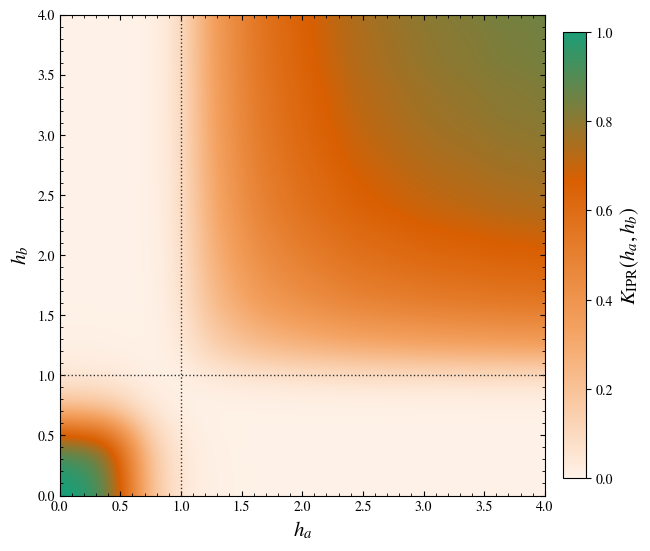

In [4]:
fig, ax, gram = plot_ipr_gram_matrix(
    dataset='tfim1d',
    L=10,
    basis=['IPR X', 'IPR Z'],
    normalize=False,
    show_title=False,
)

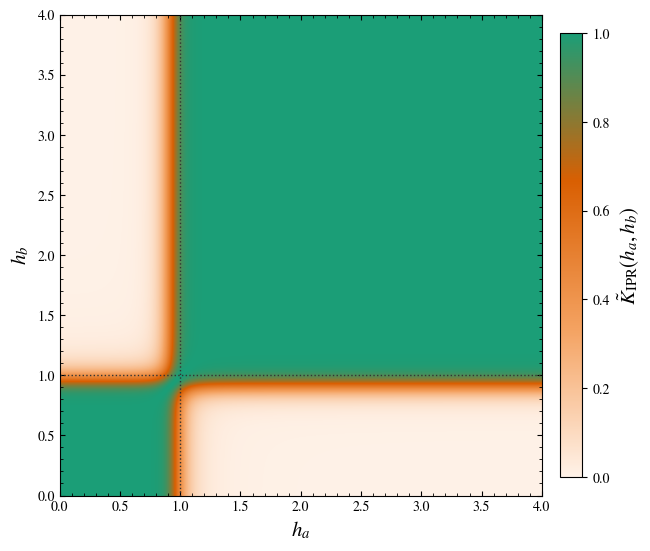

In [5]:
fig, ax, gram = plot_ipr_gram_matrix(
    dataset='tfim1d',
    L=10,
    basis=['IPR X', 'IPR Z'],
    normalize=True,
    show_title=False,
)

### TFIM 1D: selected system sizes

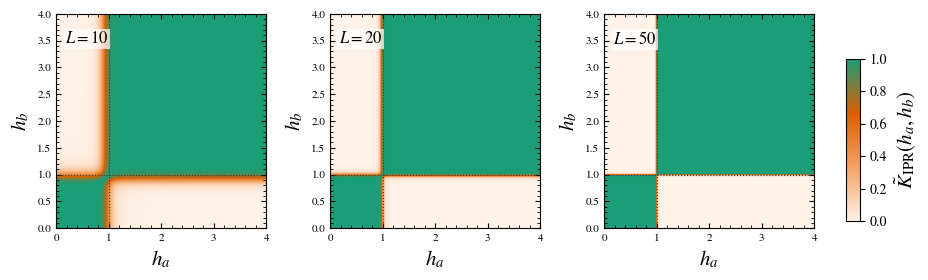

In [6]:
fig, axes, grams = plot_ipr_gram_matrices_up_to(
    dataset='tfim1d',
    basis=['IPR X', 'IPR Z'],
    L_list=[10, 20, 50],
    normalize=True,
    ncols=3,
    show_title=False,
)

### Heisenberg: X/Z and XY/Z examples

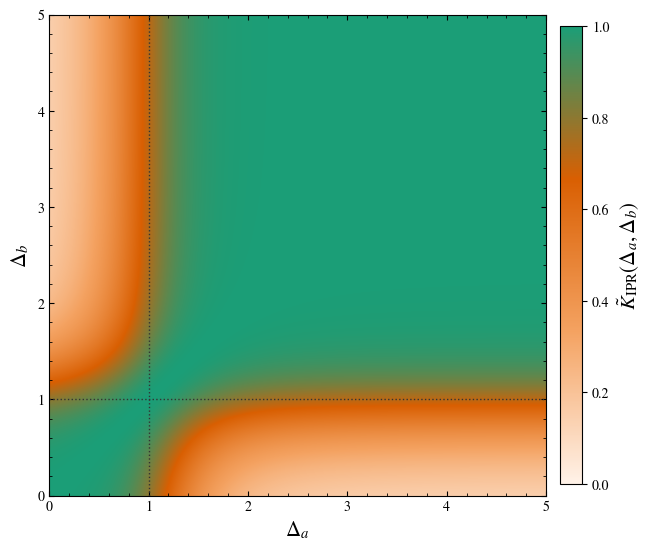

In [7]:
fig, ax, gram = plot_ipr_gram_matrix(
    dataset='heisenberg',
    L=10,
    basis=['IPR X', 'IPR Z'],
    normalize=True,
    show_title=False,
)

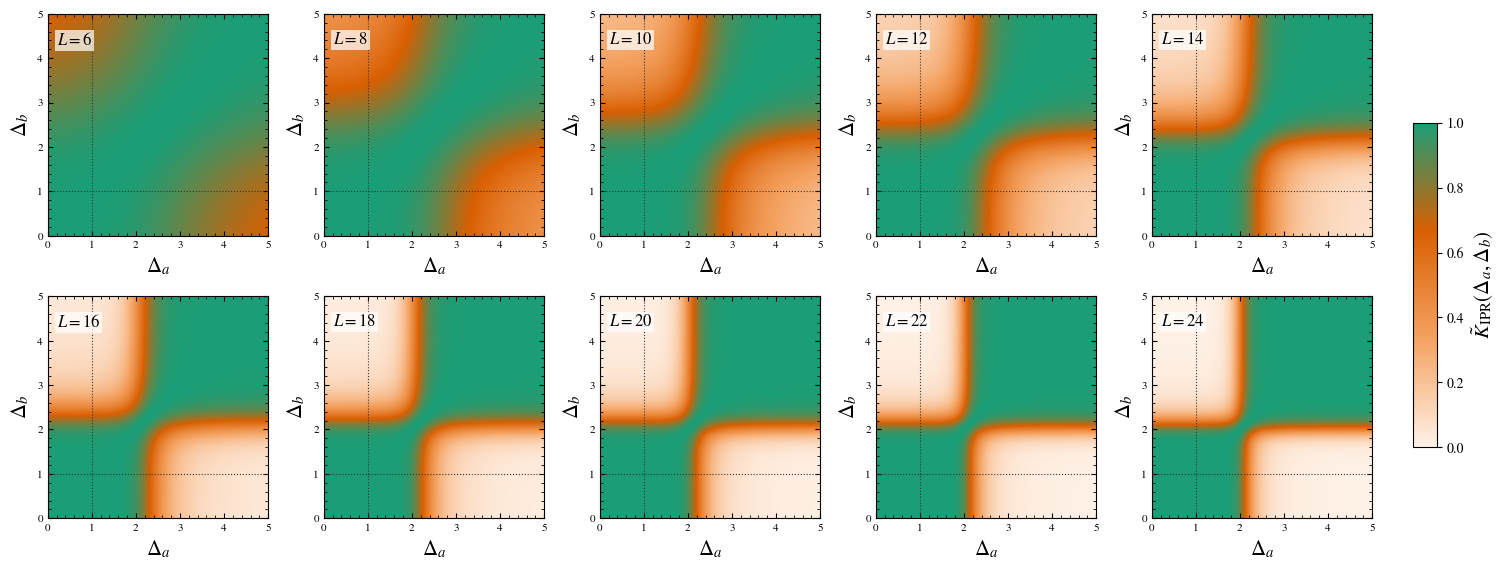

In [8]:
fig, axes, grams = plot_ipr_gram_matrices_up_to(
    dataset='heisenberg',
    basis=['IPR XY', 'IPR Z'],
    L_list=[6, 8, 10, 12, 14, 16, 18, 20, 22, 24],
    normalize=True,
    ncols=5,
    show_title=False,
)

## Thermal Grams
 
 Thermal plotting supports `kind="ipr"` and `kind="hs"`, with `source="raw"` or `source="processed"`.
 
 IPR inputs are CSV files with `h`, `beta`, `ipr_x`, and `ipr_z`; processed IPR is available only for the interpolated sizes `L=20,50,100`. IPR Grams non-log `[ipr_x, ipr_z]` features and can be normalized with the same IPR-kernel normalization used above.
 
 HS raw inputs are CSV tables with `beta`, `h_a`, `h_b`, and `kernel_real`. HS processed inputs are dense `.npy` Gram matrices. HS kernels are already normalized and are loaded as stored.
 
 The multi-plot functions require explicit `betas=[...]`.

### Thermal availability

List available system sizes and beta grids before choosing examples.

In [9]:
for kind in ['ipr', 'hs']:
    for source in ['raw', 'processed']:
        L_values = available_thermal_l_values(kind=kind, source=source)
        print(f'{kind.upper()} {source} L values:', L_values)
        if L_values:
            L0 = L_values[0]
            beta_values = available_thermal_betas(kind=kind, L=L0, source=source)
            print(f'  beta count for L={L0}:', len(beta_values))
            print('  beta range:', beta_values[0], 'to', beta_values[-1])

IPR raw L values: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
  beta count for L=10: 61
  beta range: 0.0 to 6.0
IPR processed L values: [20, 50, 100]
  beta count for L=20: 20
  beta range: 0.1 to 2.0
HS raw L values: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
  beta count for L=10: 61
  beta range: 0.0 to 6.0
HS processed L values: [20, 50, 100]
  beta count for L=20: 20
  beta range: 0.1 to 2.0


### Thermal IPR: compute raw and processed Grams

In [10]:
thermal_ipr_raw = compute_thermal_ipr_gram_matrix(
    L=20,
    beta=0.1,
    source='raw',
    normalize=True,
)
thermal_ipr_processed = compute_thermal_ipr_gram_matrix(
    L=20,
    beta=0.1,
    source='processed',
    normalize=True,
)

print('raw K shape:', thermal_ipr_raw['K'].shape)
print('processed K shape:', thermal_ipr_processed['K'].shape)
print('raw h range:', float(thermal_ipr_raw['x'].min()), float(thermal_ipr_raw['x'].max()))
print('processed h range:', float(thermal_ipr_processed['x'].min()), float(thermal_ipr_processed['x'].max()))

raw K shape: (41, 41)
processed K shape: (4000, 4000)
raw h range: 0.0 4.0
processed h range: 0.0 4.0


### Thermal generic single plots
 
 Use `plot_thermal_gram_matrix(...)` for both IPR and HS.

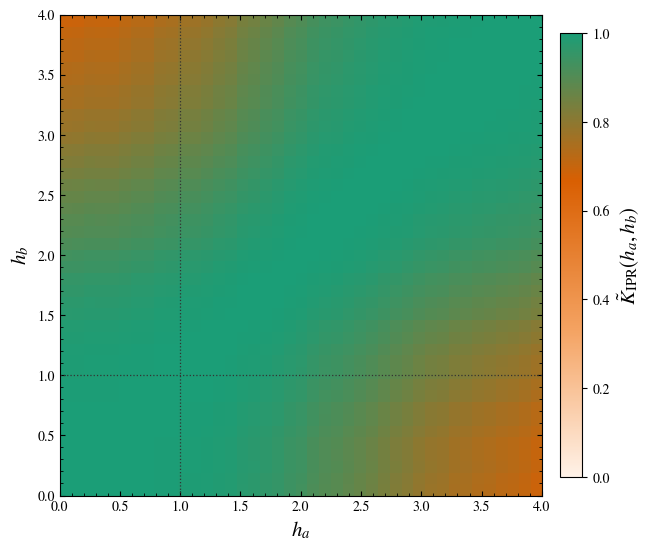

In [11]:
fig, ax, gram = plot_thermal_gram_matrix(
    kind='ipr',
    L=20,
    beta=0.1,
    source='raw',
    normalize=True,
    show_title=False,
)

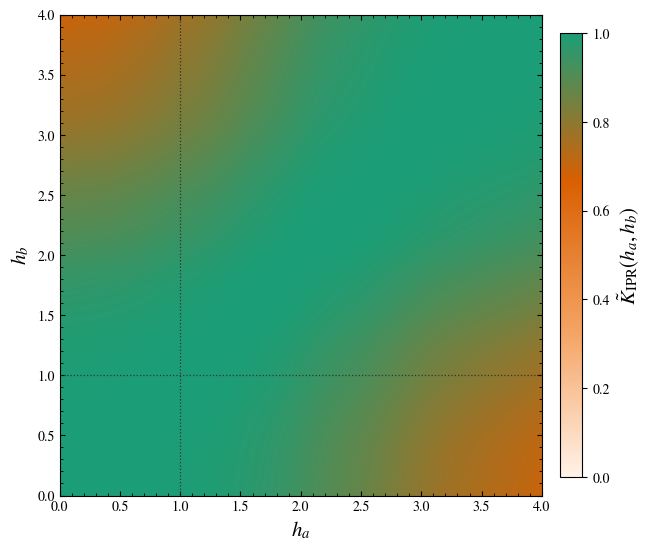

In [12]:
fig, ax, gram = plot_thermal_gram_matrix(
    kind='ipr',
    L=20,
    beta=0.1,
    source='processed',
    normalize=True,
    show_title=False,
)

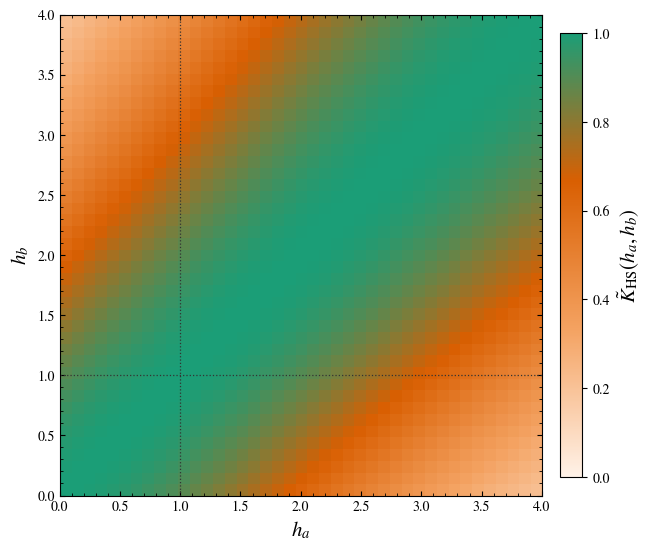

In [13]:
fig, ax, gram = plot_thermal_gram_matrix(
    kind='hs',
    L=20,
    beta=0.1,
    source='raw',
    show_title=False,
)

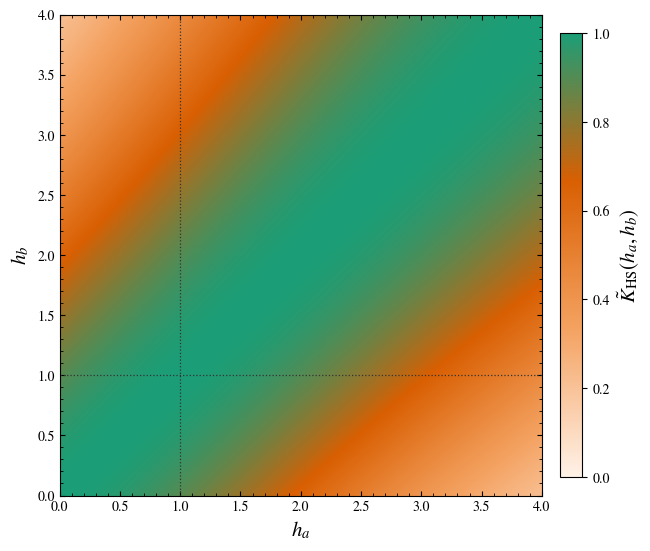

In [14]:
fig, ax, gram = plot_thermal_gram_matrix(
    kind='hs',
    L=20,
    beta=0.1,
    source='processed',
    show_title=False,
)

### Thermal generic multi-beta plots

Pass the beta values explicitly.

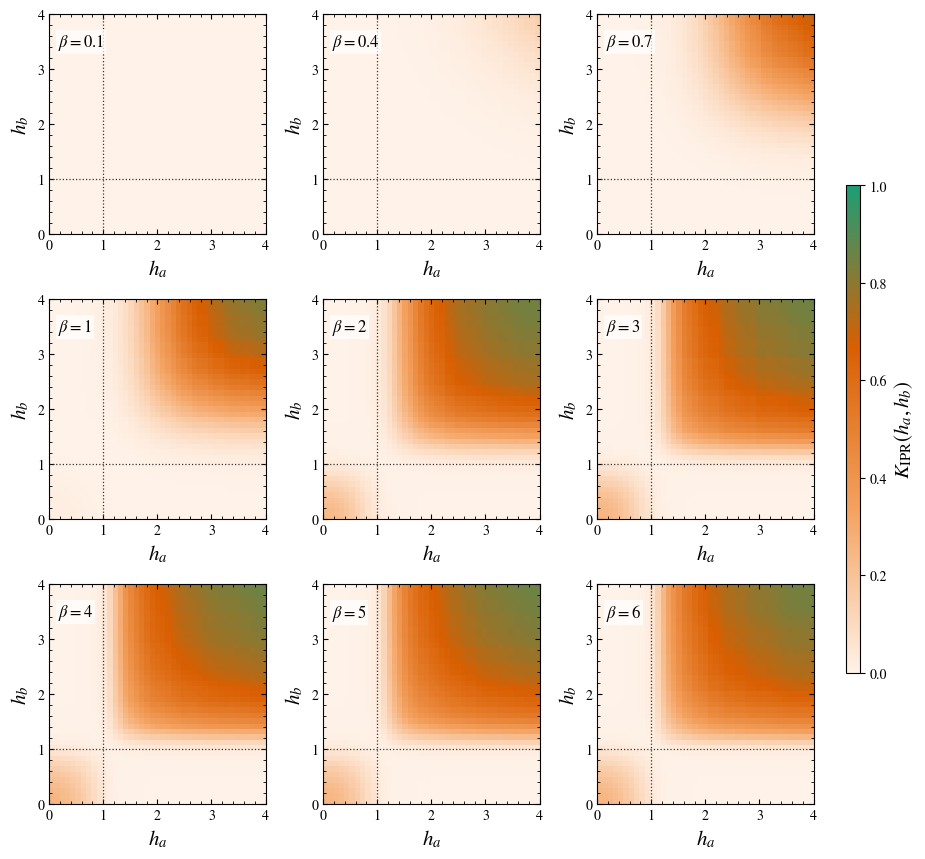

In [15]:
fig, axes, grams = plot_thermal_gram_matrices(
    kind='ipr',
    L=10,
    betas=[0.1, 0.4 ,0.7, 1, 2, 3, 4, 5, 6],
    source='raw',
    normalize=False,
    ncols=3,
    show_title=False,
)

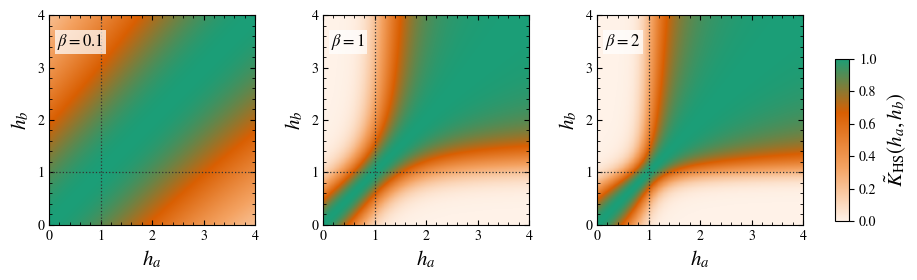

In [16]:
fig, axes, grams = plot_thermal_gram_matrices(
    kind='hs',
    L=20,
    betas=[0.1, 1.0, 2.0],
    source='processed',
    ncols=3,
    show_title=False,
)